# Forecasting Daily Taxi Demand in Chicago

Daily taxi trips in Chicago (City of Chicago Taxi Trips data, April 2022 – December 2023), forecast 30 days ahead with five time-series models evaluated on the same holdout period (December 2–31, 2023):

1. **Exploratory analysis**: trend, weekly seasonality, stationarity (ADF), ACF/PACF
2. **SARIMA**: manual specification and a BIC grid search
3. **State-space models**: Kalman filter (unobserved components) and a Hidden Markov Model
4. **Exogenous weather**: SARIMAX with daily snowfall and a transfer-function model with lagged snowfall
5. **Model comparison** on out-of-sample MAPE

In [1]:
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_percentage_error
from hmmlearn.hmm import GaussianHMM

test_mape = {}  # out-of-sample MAPE of each model on the 30-day holdout

## 1. Exploratory Data Analysis

In [2]:
taxis_df = pd.read_csv('data/taxi_rides_chicago.csv')

taxis_df.head()

,day,trips,revenue,avg_miles
0,1/1/2013,93678.0,1390215.64,3.313113
1,1/2/2013,58205.0,803292.48,3.711610
2,1/3/2013,63262.0,807470.76,3.310501
3,1/4/2013,81994.0,965673.22,3.207469
4,1/5/2013,79665.0,896401.51,3.041763


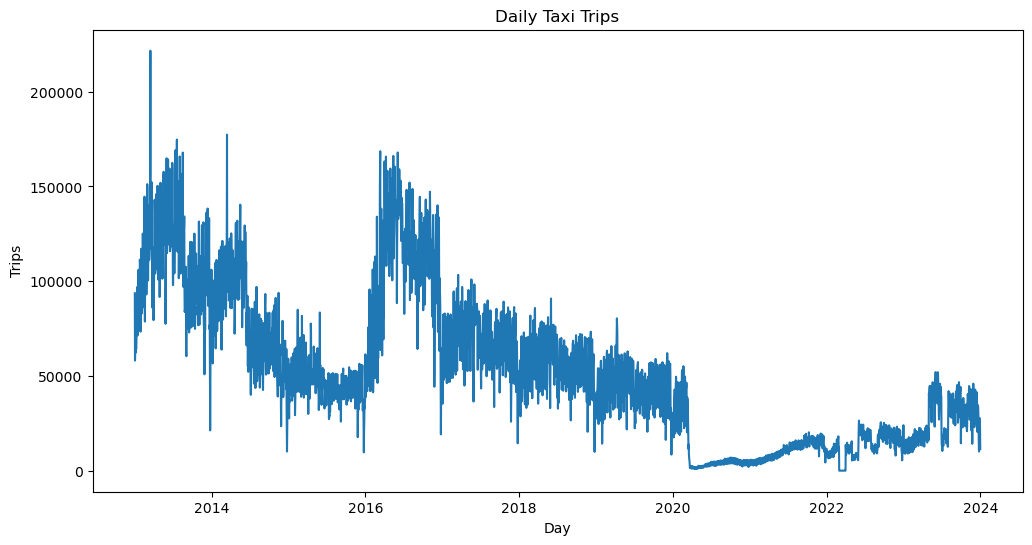

In [3]:
taxis_df['day'] = pd.to_datetime(taxis_df['day'])

plt.figure(figsize=(12, 6))
plt.plot(taxis_df['day'], taxis_df['trips'])
plt.xlabel('Day')
plt.ylabel('Trips')
plt.title('Daily Taxi Trips')
plt.show()

Taxi trips appear to have gone through a couple of trends. First a downward trend from 2013 to 2016. In 2016 we see a big increase in trips, but shortly after it starts to go down again. We see a decrease in 2020, which is probably due to the covid pandemic. After that we see an increase as things start going back to normal after covid. To avoid dealing with the covid effect and since we are mostly interested in the most recent data I am going to filter out years before 2022.

In [4]:
taxis_df_2022_2024 = taxis_df.loc[taxis_df['day'].dt.year >= 2022]
taxis_df_2022_2024.head()

,day,trips,revenue,avg_miles
3287,2022-01-01,7535.0,181365.38,5.203575
3288,2022-01-02,8489.0,287470.88,8.172459
3289,2022-01-03,10517.0,287777.42,6.654053
3290,2022-01-04,9832.0,243412.59,6.025621
3291,2022-01-05,9530.0,224032.55,5.747583


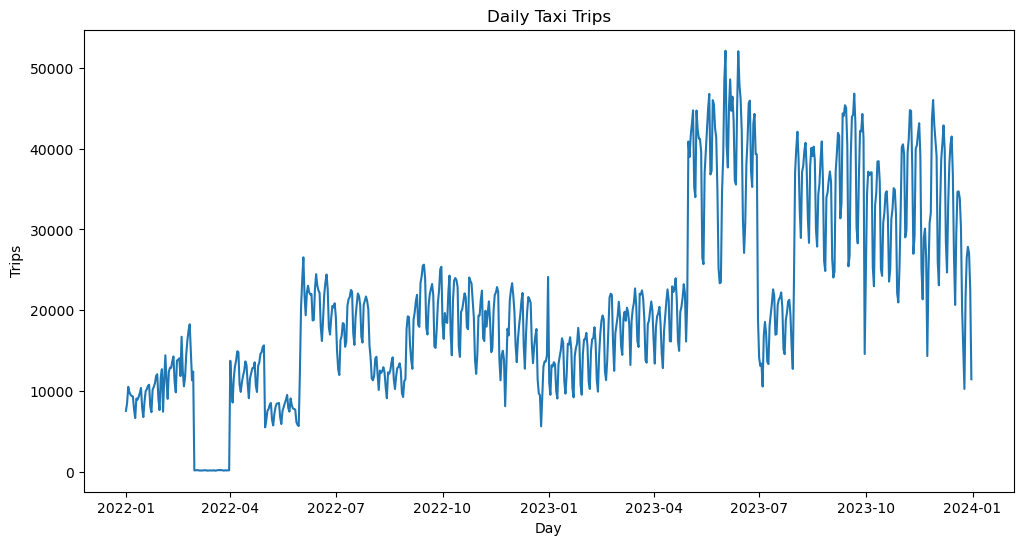

In [5]:
plt.figure(figsize=(12, 6))
plt.plot(taxis_df_2022_2024['day'], taxis_df_2022_2024['trips'])
plt.xlabel('Day')
plt.ylabel('Trips')
plt.title('Daily Taxi Trips')
plt.show()

In [6]:
trips_2022_03 = taxis_df_2022_2024[(taxis_df_2022_2024['day'].dt.year == 2022) & (taxis_df_2022_2024['day'].dt.month == 3)]
print(trips_2022_03[['day', 'trips']])

            day  trips
3346 2022-03-01  167.0
3347 2022-03-02  174.0
3348 2022-03-03  170.0
3349 2022-03-04  199.0
3350 2022-03-05  152.0
3351 2022-03-06  150.0
3352 2022-03-07  157.0
3353 2022-03-08  152.0
3354 2022-03-09  176.0
3355 2022-03-10  176.0
3356 2022-03-11  191.0
3357 2022-03-12  136.0
3358 2022-03-13  143.0
3359 2022-03-14  154.0
3360 2022-03-15  166.0
3361 2022-03-16  150.0
3362 2022-03-17  155.0
3363 2022-03-18  188.0
3364 2022-03-19  125.0
3365 2022-03-20  150.0
3366 2022-03-21  191.0
3367 2022-03-22  212.0
3368 2022-03-23  190.0
3369 2022-03-24  204.0
3370 2022-03-25  185.0
3371 2022-03-26  148.0
3372 2022-03-27  153.0
3373 2022-03-28  180.0
3374 2022-03-29  154.0
3375 2022-03-30  185.0
3376 2022-03-31  173.0


Trips in March 2022 seem to be really low, but there is no news about any kind of strike or big event that would have led to this. My current hypothesis is that there was an issue with the data for that month, so for now I will move the start date to April 2022.

The last 30 days (December 2–31, 2023) are held out as the test set for every model.

In [7]:
taxis_df_2022_04 = taxis_df_2022_2024[~((taxis_df_2022_2024['day'].dt.year == 2022) & (taxis_df_2022_2024['day'].dt.month < 4))]
taxis_df_test = taxis_df_2022_04[-30::]
taxis_df_2022_04 = taxis_df_2022_04[:-30]
taxis_df_2022_04.head()

,day,trips,revenue,avg_miles
3377,2022-04-01,13741.0,338348.15,5.508359
3378,2022-04-02,10457.0,248920.47,5.186827
3379,2022-04-03,8569.0,275226.91,7.295770
3380,2022-04-04,11568.0,379994.28,6.662176
3381,2022-04-05,13026.0,349964.59,6.018283


In [8]:
taxis_df_2022_04.tail()

,day,trips,revenue,avg_miles
3982,2023-11-27,43646.0,1254627.80,6.688804
3983,2023-11-28,46028.0,1181699.90,5.768291
3984,2023-11-29,42992.0,1176064.38,6.179698
3985,2023-11-30,41064.0,1121087.54,6.330752
3986,2023-12-01,39110.0,999755.80,5.840579


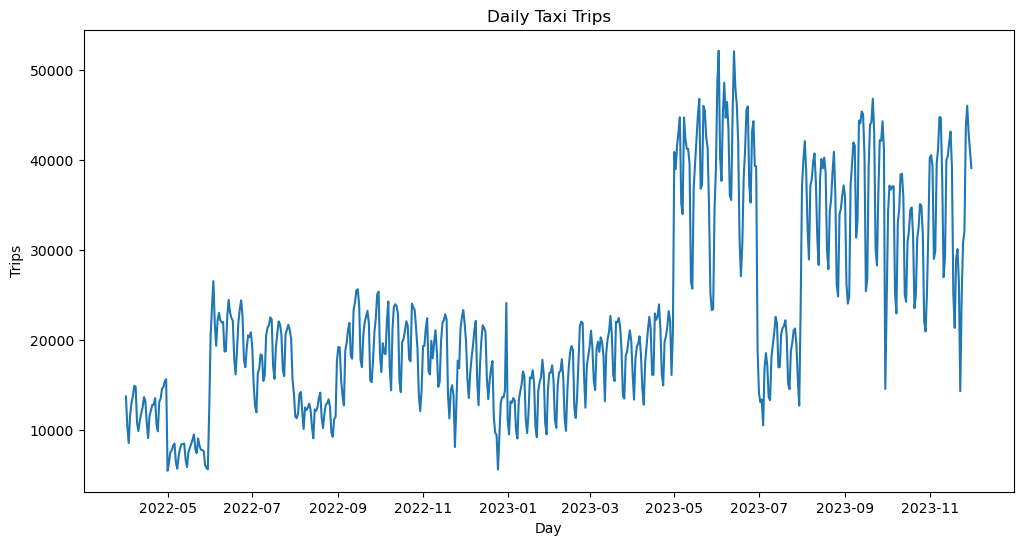

In [9]:
plt.figure(figsize=(12, 6))
plt.plot(taxis_df_2022_04['day'], taxis_df_2022_04['trips'])
plt.xlabel('Day')
plt.ylabel('Trips')
plt.title('Daily Taxi Trips')
plt.show()

In [10]:
taxis_df_2022_04 = taxis_df_2022_04.set_index('day').asfreq('D')
taxis_df_test = taxis_df_test.set_index('day').asfreq('D')
assert taxis_df_2022_04['trips'].notna().all() and taxis_df_test['trips'].notna().all()  # no missing days
taxis_df_2022_04.head()

,trips,revenue,avg_miles
day,,,
2022-04-01,13741.0,338348.15,5.508359
2022-04-02,10457.0,248920.47,5.186827
2022-04-03,8569.0,275226.91,7.295770
2022-04-04,11568.0,379994.28,6.662176
2022-04-05,13026.0,349964.59,6.018283


#### Seasonal decomposition (weekly period)

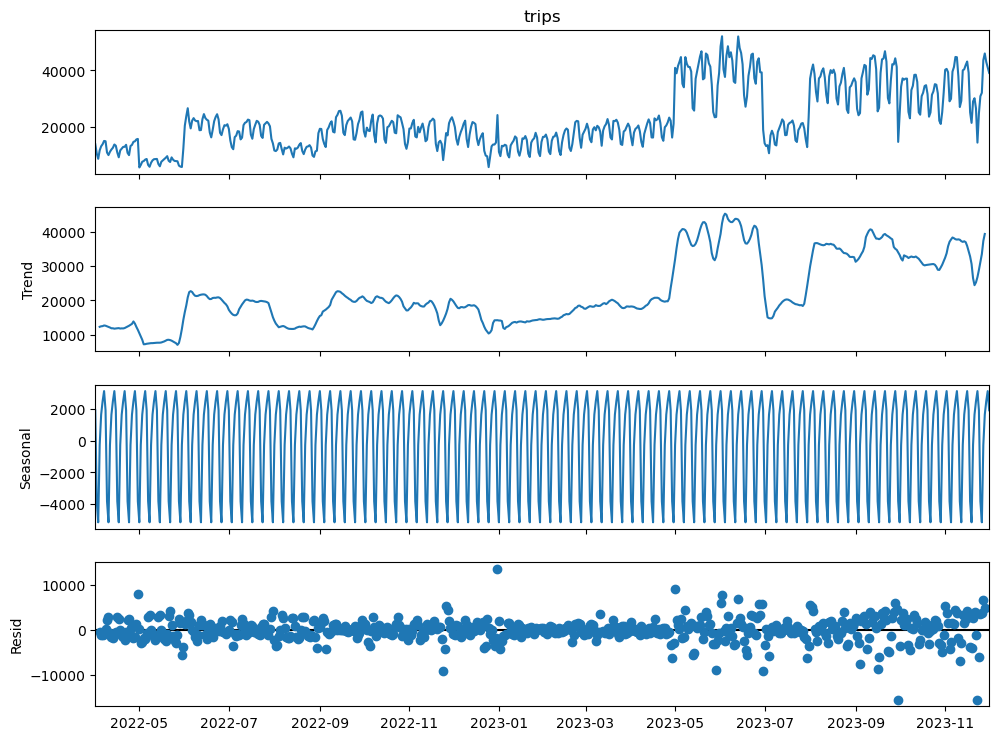

In [11]:
period = 7

decomp = seasonal_decompose(taxis_df_2022_04["trips"], model="additive", period=period)

fig = decomp.plot()
fig.set_size_inches(11, 8)
plt.show()

#### Stationarity

In [12]:
def adf_report(series, series_name="series", alpha=0.05):
    result = adfuller(series.dropna())
    test_stat, p_value, used_lag, n_obs, crit_vals, icbest = result

    print(f"\nADF test for {series_name}")
    print("----------------------------")
    print(f"Test statistic : {test_stat:.4f}")
    print(f"p-value        : {p_value:.4f}")
    print(f"Used lags      : {used_lag}")
    print(f"# of obs       : {n_obs}")
    print("Critical values:")
    for k, v in crit_vals.items():
        print(f"  {k}: {v:.4f}")

    print("\nInterpretation:")
    if p_value < alpha:
        print(f"  → p-value < {alpha}, reject H0 (unit root). Series is likely STATIONARY.")
    else:
        print(f"  → p-value ≥ {alpha}, fail to reject H0. Series is likely NONSTATIONARY.")

In [13]:
adf_report(taxis_df_2022_04["trips"], "Number of Taxi Trips in Chicago")


ADF test for Number of Taxi Trips in Chicago
----------------------------
Test statistic : -1.7585
p-value        : 0.4012
Used lags      : 19
# of obs       : 590
Critical values:
  1%: -3.4415
  5%: -2.8665
  10%: -2.5694

Interpretation:
  → p-value ≥ 0.05, fail to reject H0. Series is likely NONSTATIONARY.


In [14]:
df_diff = taxis_df_2022_04["trips"].diff().dropna()
df_diff.head()

day
2022-04-02   -3284.0
2022-04-03   -1888.0
2022-04-04    2999.0
2022-04-05    1458.0
2022-04-06     733.0
Freq: D, Name: trips, dtype: float64

In [15]:
adf_report(df_diff, "Number of Taxi Trips in Chicago")


ADF test for Number of Taxi Trips in Chicago
----------------------------
Test statistic : -7.2702
p-value        : 0.0000
Used lags      : 18
# of obs       : 590
Critical values:
  1%: -3.4415
  5%: -2.8665
  10%: -2.5694

Interpretation:
  → p-value < 0.05, reject H0 (unit root). Series is likely STATIONARY.


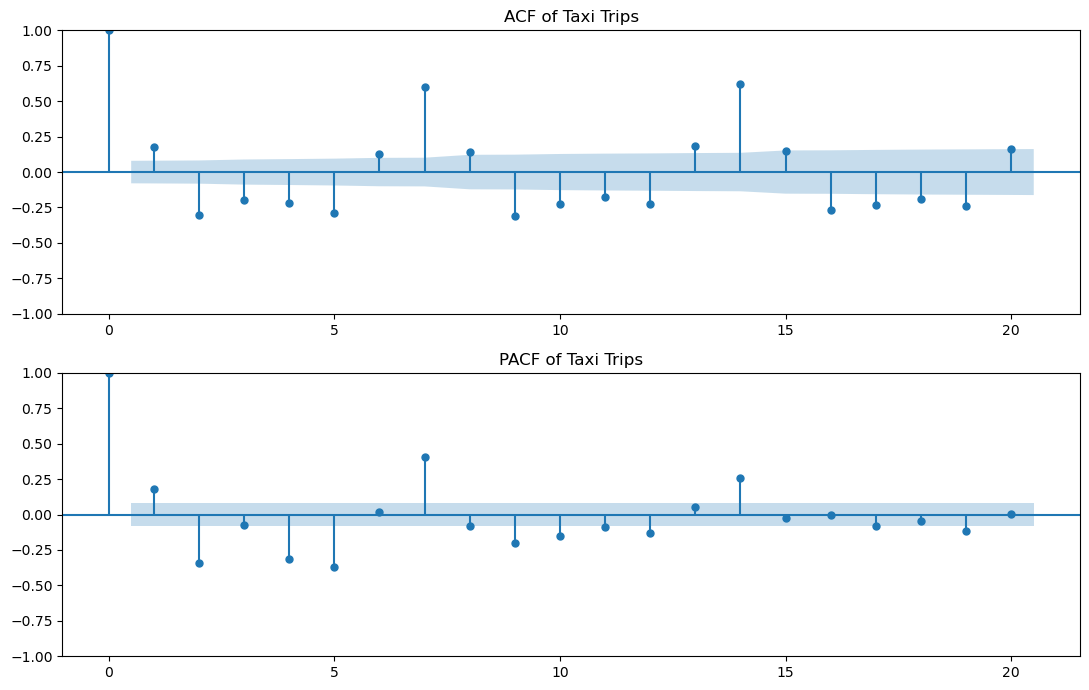

In [16]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7))
plot_acf(df_diff, lags=20, ax=axes[0])
axes[0].set_title("ACF of Taxi Trips")

plot_pacf(df_diff, lags=20, ax=axes[1])
axes[1].set_title("PACF of Taxi Trips")

plt.tight_layout()
plt.show()

## 2. SARIMA Models

After all the EDA I filtered out the data to only include daily taxi rides in Chicago from April 2022 to December 2023. I first ran the SARIMA model with the parameters I thought would be the best for the model having looked at the EDA, but later did a grid search and found the best model according to BIC.


I used the SARIMA model since the data does appear to have some seasonality to it, as we would expect demand for taxis is not the same every day, some days of the week might have more demand than others.


Focusing on the second model we can see it captures the weekly seasonality, with a statistically significant seasonal MA, which tells us that shocks from the previous week strongly affect the current value. We also have non-seasonal AR and MA which are also significant, meaning the current values are affected by the previous days value and shock. From Ljung-Box we can see that residuals aren't autocorrelated, however Jarque-Bera tells us we have to reject normality of the errors and this might have to do with the absence of exogenous variables. We can further see this in the plots at the end where we see that residuals are mostly around 0 but every now and then there is a big spike, further confirming there is something else that would help explain taxi rides besides what we already have. Overall, this seems like a good baseline, with an in-sample MAPE of 9.93%, it is a solid framework to which we could add up on with exogenous variables.


Exogenous variables I think are very important for this model. For example, holidays and special events, like Thanksgiving, Christmas, the Chicago Marathon, Bears Game. We would not expect demand to be the same for a normal Thursday than the Thursday of Thanksgiving or a normal weekend versus the weekend of a big game. Other factors I think could be very important to predict taxi trips are climate related factors such as rain, snow and  temperature. If climate is bad people may be more likely to take a taxi instead of walking. Finally, another factor to consider are competitors, with the rise of Uber, Lyft and other apps we could see that demand for taxis went down, however when looking at the most recent years I don't know what would be a good variable to use from the competitors, maybe wait times, if wait times are long it might be more likely to take a taxi, but I am not really sure what would be the best approach here. I think adding holidays, special events and climate variables should not be too hard, would just need to look for the right data to complement this dataset and that should improve this daily taxi rides model.

In [17]:
model = SARIMAX(taxis_df_2022_04['trips'],
                order=(1, 1, 1),
                seasonal_order=(1, 1, 1, 7),
                enforce_stationarity=False,
                enforce_invertibility=False)

results = model.fit(disp=False)
print(results.summary())

                                     SARIMAX Results                                     
Dep. Variable:                             trips   No. Observations:                  610
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 7)   Log Likelihood               -5580.470
Date:                           Sat, 24 Oct 2026   AIC                          11170.940
Time:                                   09:33:27   BIC                          11192.866
Sample:                               04-01-2022   HQIC                         11179.480
                                    - 12-01-2023                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.6654      0.170     -3.924      0.000      -0.998      -0.333
ma.L1          0.7484      0.163      4.587

Grid search over the (p, d, q)(P, D, Q, 7) orders, ranked by BIC:

In [18]:
def optimize_sarima_bic(y, p_range, d_range, q_range, P_range, D_range, Q_range, s):

    pdq = list(itertools.product(p_range, d_range, q_range))
    seasonal_pdq = list(itertools.product(P_range, D_range, Q_range, [s]))

    results_list = []
    best_bic = float('inf')
    best_model_params = None

    total_combinations = len(pdq) * len(seasonal_pdq)
    print(f"Testing {total_combinations} combinations...")

    for param in pdq:
        for param_seasonal in seasonal_pdq:
            try:
                mod = SARIMAX(y,
                              order=param,
                              seasonal_order=param_seasonal,
                              enforce_stationarity=False,
                              enforce_invertibility=False)

                results = mod.fit(disp=False)

                results_list.append({
                    'order': param,
                    'seasonal_order': param_seasonal,
                    'AIC': results.aic,
                    'BIC': results.bic
                })

                if results.bic < best_bic:
                    best_bic = results.bic
                    best_model_params = (param, param_seasonal)

            except Exception as e:
                continue

    results_df = pd.DataFrame(results_list)
    if not results_df.empty:
        results_df = results_df.sort_values(by='BIC').reset_index(drop=True)

    return best_model_params, results_df

In [19]:
p_range = range(0, 2)
d_range = [1]
q_range = range(0, 2)

P_range = range(0, 2)
D_range = [1]
Q_range = range(0, 2)
s = 7

best_params, all_results = optimize_sarima_bic(taxis_df_2022_04['trips'], p_range, d_range, q_range,
                                               P_range, D_range, Q_range, s)

print("\n--- Best Model Found ---")
print("Parameters:", best_params)
print("\n--- Top 5 Models by BIC ---")
print(all_results.head())

Testing 16 combinations...



--- Best Model Found ---
Parameters: ((0, 1, 1), (1, 1, 1, 7))

--- Top 5 Models by BIC ---
       order seasonal_order           AIC           BIC
0  (0, 1, 1)   (1, 1, 1, 7)  11175.293188  11192.833965
1  (1, 1, 1)   (1, 1, 1, 7)  11170.940265  11192.866237
2  (0, 1, 0)   (0, 1, 1, 7)  11190.724399  11199.498158
3  (1, 1, 0)   (0, 1, 1, 7)  11191.566688  11204.727326
4  (0, 1, 0)   (1, 1, 1, 7)  11192.599199  11205.759837


Final SARIMA(1, 1, 1)(0, 1, 1, 7) model:

In [20]:
model = SARIMAX(taxis_df_2022_04['trips'],
                order=(1, 1, 1),
                seasonal_order=(0, 1, 1, 7),
                enforce_stationarity=False,
                enforce_invertibility=False)

results = model.fit(disp=False)
print(results.summary())

                                     SARIMAX Results                                     
Dep. Variable:                             trips   No. Observations:                  610
Model:             SARIMAX(1, 1, 1)x(0, 1, 1, 7)   Log Likelihood               -5614.985
Date:                           Sat, 24 Oct 2026   AIC                          11237.969
Time:                                   09:33:37   BIC                          11255.510
Sample:                               04-01-2022   HQIC                         11244.801
                                    - 12-01-2023                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.6537      0.282     -2.319      0.020      -1.206      -0.101
ma.L1          0.7373      0.271      2.716

In [21]:
mape = mean_absolute_percentage_error(taxis_df_2022_04['trips'], results.fittedvalues)
print(f"In-sample MAPE: {mape*100:.2f}%")

In-sample MAPE: 9.93%


30-day forecast on the holdout:

In [22]:
fc = results.get_forecast(30)
forecast_values = fc.predicted_mean
forecast_values

2023-12-02    30243.880308
2023-12-03    30388.548930
2023-12-04    38956.884434
2023-12-05    41446.874982
2023-12-06    42302.038899
2023-12-07    40930.988593
2023-12-08    39672.343833
2023-12-09    30937.589354
2023-12-10    30996.380582
2023-12-11    39620.856724
2023-12-12    42074.146447
2023-12-13    42953.302798
2023-12-14    41566.567916
2023-12-15    40318.176635
2023-12-16    31576.719148
2023-12-17    31639.892335
2023-12-18    40261.503858
2023-12-19    42716.666269
2023-12-20    43594.598387
2023-12-21    42208.663822
2023-12-22    40959.749350
2023-12-23    32218.633889
2023-12-24    32281.583483
2023-12-25    40903.341176
2023-12-26    43358.408031
2023-12-27    44236.402617
2023-12-28    42850.427215
2023-12-29    41601.539440
2023-12-30    32860.406526
2023-12-31    32923.367529
Freq: D, Name: predicted_mean, dtype: float64

In [23]:
mape = mean_absolute_percentage_error(taxis_df_test['trips'], forecast_values)
print(f"MAPE: {mape*100:.2f}%")
test_mape["SARIMA(1,1,1)(0,1,1,7)"] = mape

MAPE: 45.19%


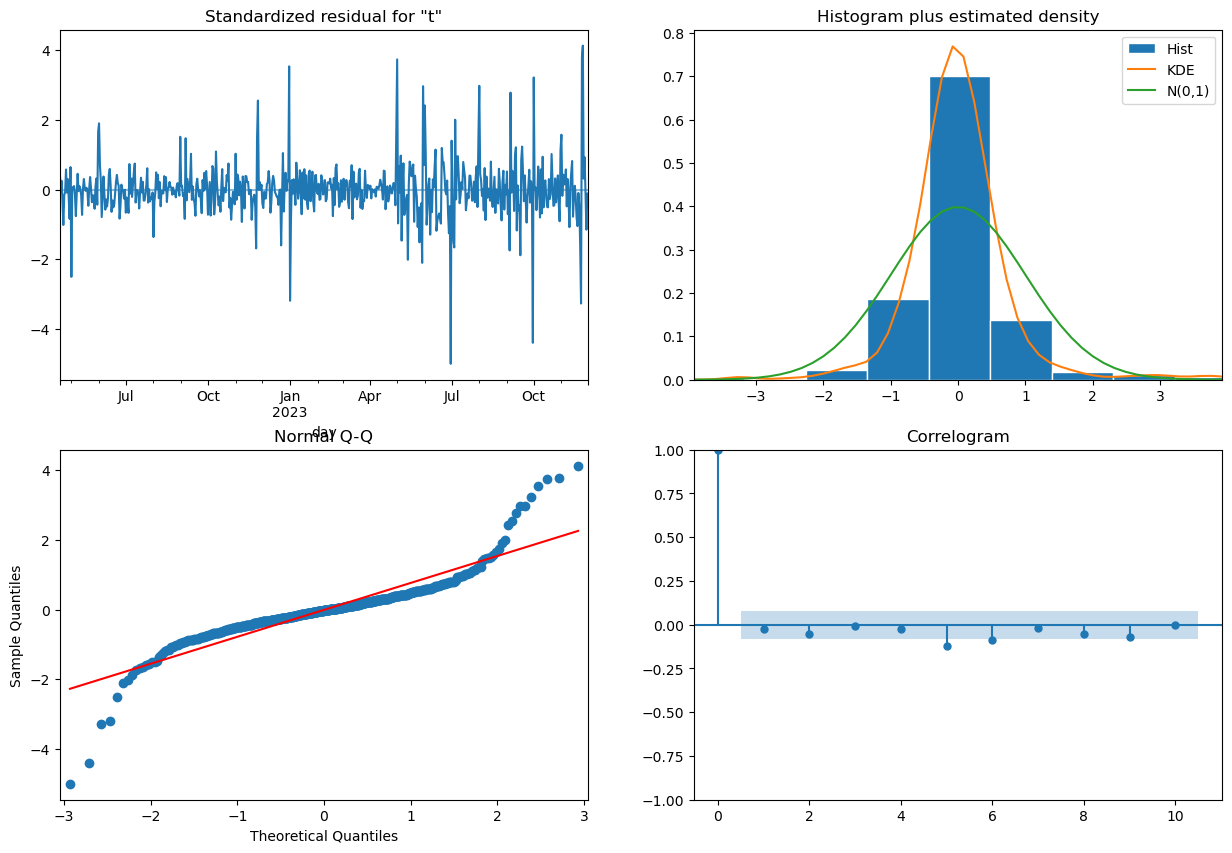

In [24]:
results.plot_diagnostics(figsize=(15, 10))
plt.show()

## 3. State-Space Models

Diving into the State Space Models for the first time I don't have as much intuition as to which will work best for this dataset. Based on what I have researched so far I think Kalman-Filter will be the best performing one since the SARIMA model showed there is a weekly seasonal pattern in the data, plus it seems we have the level and trend changing a little over time.

I ran Kalman-Filter and Hidden Markov models and Kalman-Filter was the best performing one. I tried running Bayesian Time Series as well, but had issues with the library. From the summary of the Kalman-Filter Model we can see that the level is significant, meaning it changes over time; the trend is not significant; seasonal is significant so the weekly seasonality is real and important which follows what the SARIMA model indicated. With Ljung-Box Test we see there is no autocorrelation in the residuals, but Jarque-Bera indicates they are not normally distributed. We also get a MAPE of 35% when comparing the last 30 days of the series which is better than the MAPE from the SARIMA Model at 45%. For the Hidden Markov Model we end up with a MAPE of 54%, which is bigger than our baseline SARIMA. Finally, when looking at the plot we see that the forecast follows very closely the actual values in the first days, but later they diverge a bit due to trips dropping.

Similar to the case with SARIMA using exogenous variables could improve our Kalman-Filter model. Holidays, special events and weather could help explain better the demand for taxis in Chicago. For example, the drop in demand that our forecast is not picking up on could be due to snow or maybe due to the Christmas holiday time people spend less time going out.

### Kalman filter (unobserved components: local linear trend + weekly seasonal)

In [25]:
y_train = taxis_df_2022_04['trips']
y_log = np.log(y_train)

y_test = taxis_df_test['trips']

mod = sm.tsa.UnobservedComponents(
    y_log,
    level="local linear trend",
    seasonal=7
)

res = mod.fit()
print(res.summary())

                           Unobserved Components Results                            
Dep. Variable:                        trips   No. Observations:                  610
Model:                   local linear trend   Log Likelihood                 325.555
                   + stochastic seasonal(7)   AIC                           -643.110
Date:                      Sat, 24 Oct 2026   BIC                           -625.509
Time:                              09:33:37   HQIC                          -636.259
Sample:                          04-01-2022                                         
                               - 12-01-2023                                         
Covariance Type:                        opg                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
sigma2.irregular     0.0003      0.000      0.703      0.482     

In [26]:
fc = res.get_forecast(steps=30)
forecast = np.exp(fc.predicted_mean)
ci_log = fc.conf_int()
lower = np.exp(ci_log.iloc[:, 0])
upper = np.exp(ci_log.iloc[:, 1])

print(forecast)

2023-12-02    28256.106691
2023-12-03    27414.562410
2023-12-04    35527.274772
2023-12-05    38239.087537
2023-12-06    40869.194121
2023-12-07    39672.005573
2023-12-08    39617.950675
2023-12-09    28597.867872
2023-12-10    27746.145006
2023-12-11    35956.981650
2023-12-12    38701.594132
2023-12-13    41363.512188
2023-12-14    40151.843493
2023-12-15    40097.134794
2023-12-16    28943.762697
2023-12-17    28081.738136
2023-12-18    36391.885886
2023-12-19    39169.694803
2023-12-20    41863.809094
2023-12-21    40637.485113
2023-12-22    40582.114706
2023-12-23    29293.841164
2023-12-24    28421.390307
2023-12-25    36832.050344
2023-12-26    39643.457211
2023-12-27    42370.157155
2023-12-28    41129.000630
2023-12-29    41072.960511
2023-12-30    29648.153874
2023-12-31    28765.150614
Freq: D, Name: predicted_mean, dtype: float64


In [27]:
y_test

day
2023-12-02    25964.0
2023-12-03    23088.0
2023-12-04    32670.0
2023-12-05    38656.0
2023-12-06    40628.0
2023-12-07    42888.0
2023-12-08    39892.0
2023-12-09    28494.0
2023-12-10    24674.0
2023-12-11    33150.0
2023-12-12    38074.0
2023-12-13    40514.0
2023-12-14    41512.0
2023-12-15    36892.0
2023-12-16    26676.0
2023-12-17    20656.0
2023-12-18    29560.0
2023-12-19    34662.0
2023-12-20    34718.0
2023-12-21    33858.0
2023-12-22    30284.0
2023-12-23    20168.0
2023-12-24    15352.0
2023-12-25    10258.0
2023-12-26    21736.0
2023-12-27    26536.0
2023-12-28    27842.0
2023-12-29    27058.0
2023-12-30    22570.0
2023-12-31    11452.0
Freq: D, Name: trips, dtype: float64

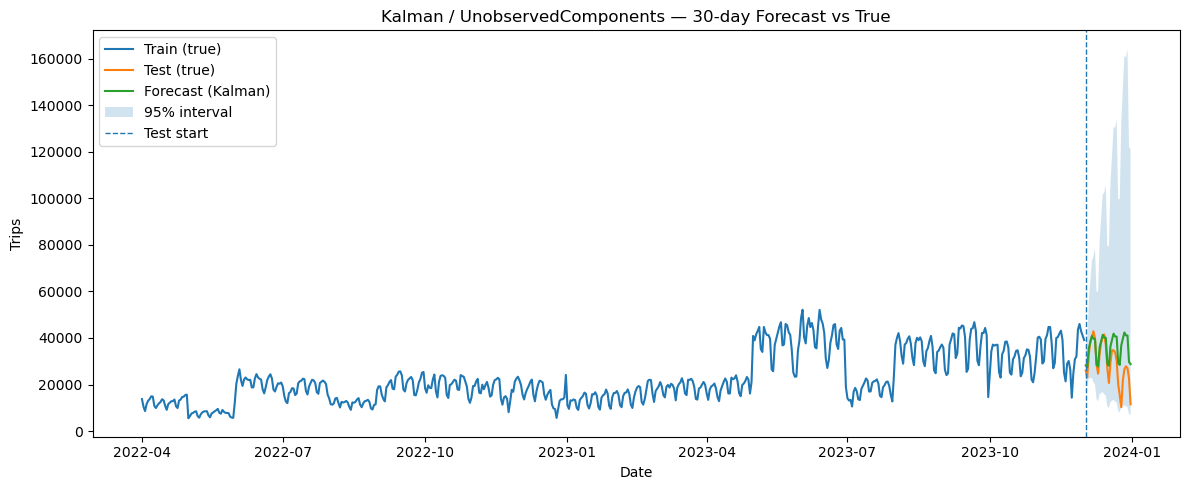

In [28]:
forecast.index = y_test.index
lower.index = y_test.index
upper.index = y_test.index

plt.figure(figsize=(12, 5))
plt.plot(y_train.index, y_train.values, label="Train (true)")
plt.plot(y_test.index,  y_test.values,  label="Test (true)")
plt.plot(forecast.index,    forecast.values,    label="Forecast (Kalman)")
plt.fill_between(forecast.index, lower.values, upper.values, alpha=0.2, label="95% interval")
plt.axvline(y_test.index[0], linestyle="--", linewidth=1, label="Test start")
plt.title("Kalman / UnobservedComponents — 30-day Forecast vs True")
plt.xlabel("Date")
plt.ylabel("Trips")
plt.legend()
plt.tight_layout()
plt.show()

In [29]:
mape = mean_absolute_percentage_error(taxis_df_test['trips'], forecast)
print(f"MAPE: {mape*100:.2f}%")
test_mape["Kalman filter (UC)"] = mape

MAPE: 35.06%


### Hidden Markov Model
Seasonal-naive baseline (repeat the last observed week) plus a 3-state Gaussian HMM fitted on the week-over-week differences, which forecasts the expected deviation from the baseline.

In [30]:
hmm_taxis = pd.concat([taxis_df_2022_04, taxis_df_test])
hmm_taxis

,trips,revenue,avg_miles
day,,,
2022-04-01,13741.0,338348.15,5.508359
2022-04-02,10457.0,248920.47,5.186827
2022-04-03,8569.0,275226.91,7.295770
2022-04-04,11568.0,379994.28,6.662176
2022-04-05,13026.0,349964.59,6.018283
...,...,...,...
2023-12-27,26536.0,701994.56,6.586632
2023-12-28,27842.0,703144.60,6.135375
2023-12-29,27058.0,686489.66,6.165258


In [31]:
H = 30

y = hmm_taxis["trips"].asfreq("D")

train = y.iloc[:-H]
test  = y.iloc[-H:]

train_end = train.index[-1]
future_idx = test.index

last_week = train.iloc[-7:].values
baseline_vals = np.tile(last_week, int(np.ceil(H/7)))[:H]
baseline_fc = pd.Series(baseline_vals, index=future_idx)

resid = (train - train.shift(7)).dropna()
X = resid.values.reshape(-1, 1)

In [32]:
K = 3
hmm = GaussianHMM(n_components=K, covariance_type="diag", n_iter=300, random_state=42)
hmm.fit(X)

state_probs = hmm.predict_proba(X)
p = state_probs[-1]

T = hmm.transmat_
mu = hmm.means_.ravel()

resid_fc = []
p_h = p.copy()

for _ in range(H):
    p_h = p_h @ T
    resid_fc.append(p_h @ mu)

resid_fc = pd.Series(resid_fc, index=future_idx)

In [33]:
hmm_forecast = baseline_fc + resid_fc
hmm_forecast

day
2023-12-02    41871.937740
2023-12-03    40955.476988
2023-12-04    50908.544230
2023-12-05    51908.813616
2023-12-06    47818.370441
2023-12-07    44992.342006
2023-12-08    42368.425621
2023-12-09    33496.229896
2023-12-10    34289.195958
2023-12-11    45510.199531
2023-12-12    47627.511333
2023-12-13    44336.487964
2023-12-14    42245.206720
2023-12-15    40120.290518
2023-12-16    31735.808195
2023-12-17    32835.454494
2023-12-18    44384.243655
2023-12-19    46685.412295
2023-12-20    43618.360820
2023-12-21    41632.773021
2023-12-22    39664.182181
2023-12-23    31335.911762
2023-12-24    32547.564622
2023-12-25    44121.487867
2023-12-26    46505.406430
2023-12-27    43444.204485
2023-12-28    41521.850032
2023-12-29    39547.366862
2023-12-30    31269.125472
2023-12-31    32467.954622
Freq: D, dtype: float64

In [34]:
print("Means:", hmm.means_)
print("Covars:", hmm.covars_)
print("Transition matrix:\n", hmm.transmat_)
print("Initial probabilities:\n", hmm.startprob_)
print("Log-likelihood:", hmm.score(X))

Means: [[ -945.19412358]
 [-1034.71956406]
 [13653.69842574]]
Covars: [[[22625151.0237001 ]]

 [[27476825.64436452]]

 [[29133248.41900211]]]
Transition matrix:
 [[2.78010102e-03 9.97071690e-01 1.48208589e-04]
 [9.53196871e-01 9.46127700e-03 3.73418519e-02]
 [1.65665187e-01 1.15280087e-02 8.22806804e-01]]
Initial probabilities:
 [9.98925741e-01 1.07425880e-03 1.22071450e-20]
Log-likelihood: -6049.814664255812


In [35]:
mape = mean_absolute_percentage_error(taxis_df_test['trips'], hmm_forecast)
print(f"MAPE: {mape*100:.2f}%")
test_mape["Hidden Markov Model"] = mape

MAPE: 54.38%


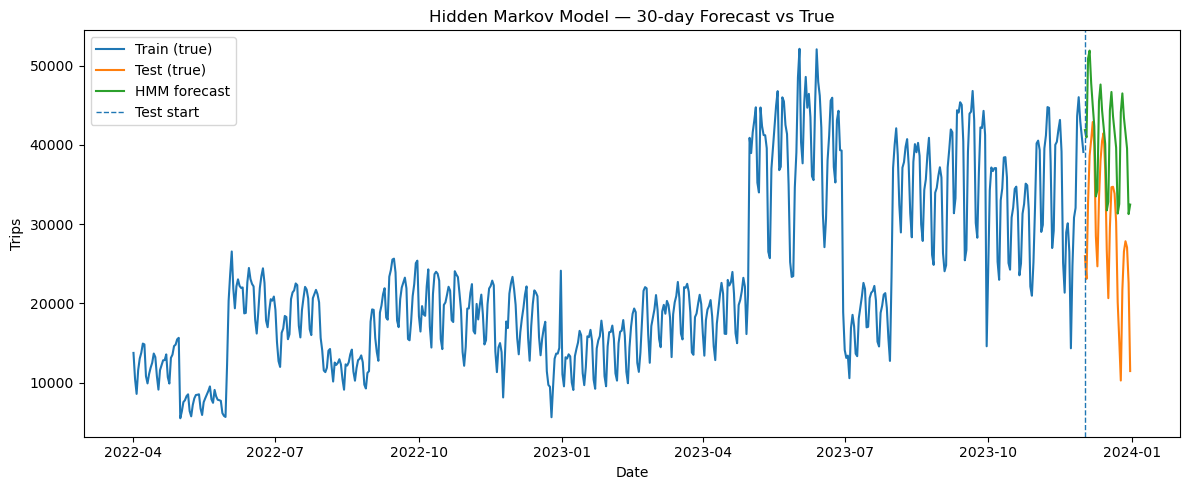

In [36]:
plt.figure(figsize=(12, 5))
plt.plot(train.index, train.values, label="Train (true)")
plt.plot(test.index,  test.values,  label="Test (true)")
plt.plot(hmm_forecast.index,  hmm_forecast.values,  label="HMM forecast")
plt.axvline(test.index[0], linestyle="--", linewidth=1, label="Test start")
plt.title("Hidden Markov Model — 30-day Forecast vs True")
plt.xlabel("Date")
plt.ylabel("Trips")
plt.legend()
plt.tight_layout()
plt.show()

## 4. Exogenous Snowfall: SARIMAX and Transfer Function Model

First I started with running a SARIMAX model adding an exogenous variable of snow to have a baseline to compare the Transfer Function Model to. However, here I found that snow was not statistically significant to the model. Thinking that maybe the Transfer Function Model would have a more interesting result, where maybe lagged snow was actually significant to predicting taxi demand (maybe people avoided going out after a snow day or decided to take a taxi instead of walking). However, snow lag also was not statistically significant. For the future I will try to search for other exogenous variables which might explain taxi demand. The SARIMAX has the lower MAPE (38.47% vs. 45.64% for the Transfer Function Model), and when looking at the plot of both models the SARIMAX I would say performs better because it follows very closely the first couple of days, versus the Transfer Function Model which gets the direction but without the seasonality, so even in the first couple of days we see that the prediction diverges.

Daily snowfall (inches) at Chicago O'Hare (ORD):

In [37]:
snow_df = pd.read_csv('data/chicago_snowfall_2022_2024.csv')
snow_df.head()

,day,snow_in
0,1/1/2022,3.2
1,1/2/2022,0.9
2,1/3/2022,0.0
3,1/4/2022,0.0
4,1/5/2022,0.1


In [38]:
y_train = taxis_df_2022_04.copy()
y_train.index = pd.to_datetime(y_train.index)
y_train = y_train.sort_index()

y_test = taxis_df_test.copy().sort_index()

snow_df["day"] = pd.to_datetime(snow_df["day"])
snow_df = snow_df.set_index("day").sort_index()

In [39]:
train = y_train.join(snow_df["snow_in"], how="left")

test = y_test.join(snow_df["snow_in"], how="left")

train["snow_in"] = train["snow_in"].fillna(0)
test["snow_in"] = test["snow_in"].fillna(0)

In [40]:
y_train_series = train["trips"]
X_train = train[["snow_in"]]

y_test_series = test["trips"]
X_test = test[["snow_in"]]

### SARIMAX with snowfall

In [41]:
y_train_log = np.log1p(y_train_series)

In [42]:
model = sm.tsa.SARIMAX(
    y_train_log,
    exog=X_train,
    order=(1,1,1),
    seasonal_order=(0,1,1,7),
    enforce_stationarity=False,
    enforce_invertibility=False
)

results = model.fit(disp=False)

print(results.summary())

                                     SARIMAX Results                                     
Dep. Variable:                             trips   No. Observations:                  610
Model:             SARIMAX(1, 1, 1)x(0, 1, 1, 7)   Log Likelihood                 321.324
Date:                           Sat, 24 Oct 2026   AIC                           -632.648
Time:                                   09:33:41   BIC                           -610.722
Sample:                               04-01-2022   HQIC                          -624.108
                                    - 12-01-2023                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
snow_in       -0.0121      0.022     -0.547      0.584      -0.055       0.031
ar.L1         -0.7516      0.197     -3.808

In [43]:
forecast_log = results.get_forecast(
    steps=len(y_test_series),
    exog=X_test
).predicted_mean

forecast = np.expm1(forecast_log)

In [44]:
mape = mean_absolute_percentage_error(y_test_series, forecast)
print(f"MAPE: {mape*100:.2f}%")
test_mape["SARIMAX + snow (log)"] = mape

MAPE: 38.47%


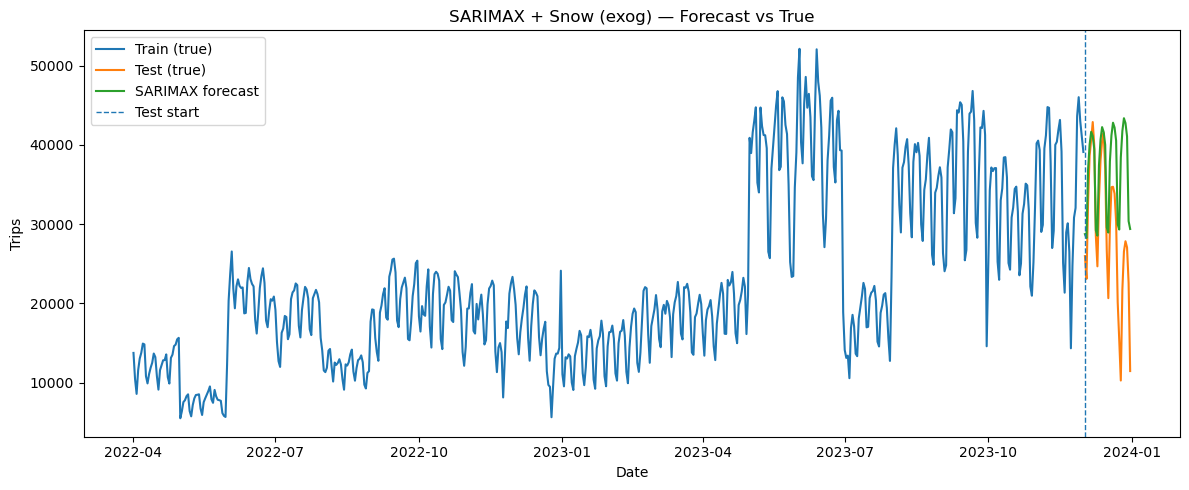

In [45]:
sarimax_forecast = pd.Series(forecast.values, index=y_test_series.index, name="SARIMAX Forecast")

plt.figure(figsize=(12, 5))
plt.plot(y_train_series.index, y_train_series.values, label="Train (true)")
plt.plot(y_test_series.index,  y_test_series.values,  label="Test (true)")
plt.plot(sarimax_forecast.index, sarimax_forecast.values, label="SARIMAX forecast")
plt.axvline(y_test_series.index[0], linestyle="--", linewidth=1, label="Test start")
plt.title("SARIMAX + Snow (exog) — Forecast vs True")
plt.xlabel("Date")
plt.ylabel("Trips")
plt.legend()
plt.tight_layout()
plt.show()

### Transfer function model (snowfall lags 0–5)

In [46]:
max_lag = 5

for L in range(max_lag + 1):
    train[f"snow_lag{L}"] = train["snow_in"].shift(L)

train = train.dropna()

In [47]:
y_tf = np.log1p(train["trips"])
X_tf = train[[f"snow_lag{L}" for L in range(max_lag + 1)]]

In [48]:
model_tf = sm.tsa.SARIMAX(
    y_tf,
    exog=X_tf,
    order=(1,0,1),
    seasonal_order=(0,0,0,0),
    enforce_stationarity=False,
    enforce_invertibility=False
)

results_tf = model_tf.fit(disp=False, maxiter=1000)  # the default 50 iterations do not converge
print(results_tf.summary())

                               SARIMAX Results                                
Dep. Variable:                  trips   No. Observations:                  605
Model:               SARIMAX(1, 0, 1)   Log Likelihood                 129.489
Date:                Sat, 24 Oct 2026   AIC                           -240.978
Time:                        09:33:42   BIC                           -201.361
Sample:                    04-06-2022   HQIC                          -225.559
                         - 12-01-2023                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
snow_lag0     -0.0114      0.056     -0.202      0.840      -0.122       0.099
snow_lag1     -0.0119      0.072     -0.166      0.868      -0.153       0.129
snow_lag2     -0.0802      0.080     -1.001      0.3

In [49]:
combined = pd.concat([train[["snow_in"]], test[["snow_in"]]])

for L in range(max_lag + 1):
    combined[f"snow_lag{L}"] = combined["snow_in"].shift(L)

X_test_tf = combined.loc[y_test.index, [f"snow_lag{L}" for L in range(max_lag + 1)]]

In [50]:
forecast_log = results_tf.get_forecast(
    steps=len(y_test),
    exog=X_test_tf
).predicted_mean

forecast_tf = np.expm1(forecast_log)

In [51]:
mape_tf = mean_absolute_percentage_error(y_test["trips"], forecast_tf)
print(f"MAPE: {mape_tf*100:.2f}%")
test_mape["Transfer function (snow lags)"] = mape_tf

MAPE: 45.64%


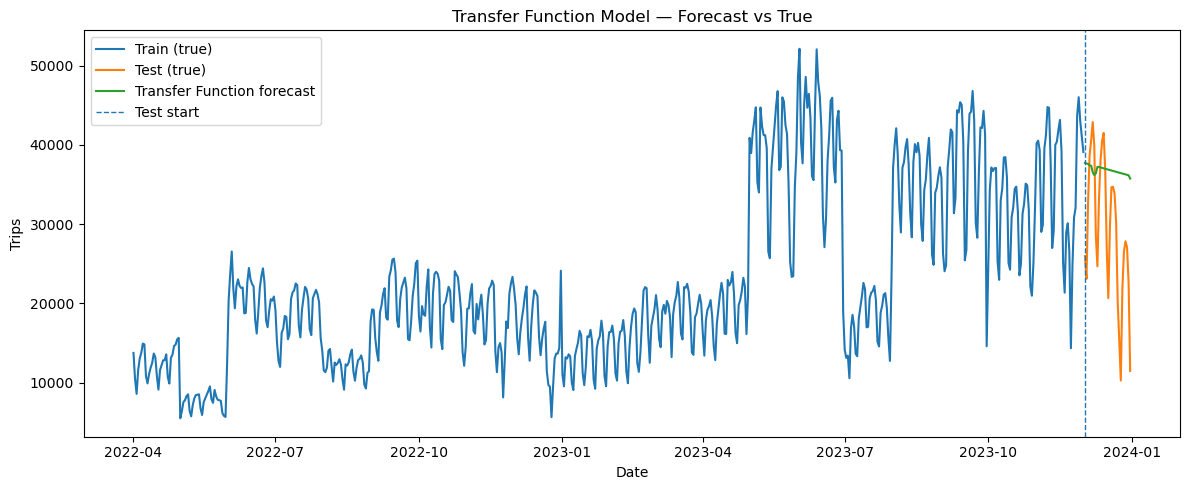

In [52]:
tf_forecast_series = pd.Series(
    forecast_tf.values,
    index=y_test.index,
    name="Transfer Function Forecast"
)

plt.figure(figsize=(12, 5))

plt.plot(y_train.index, y_train["trips"], label="Train (true)")
plt.plot(y_test.index, y_test["trips"], label="Test (true)")
plt.plot(tf_forecast_series.index, tf_forecast_series.values, label="Transfer Function forecast")

plt.axvline(y_test.index[0], linestyle="--", linewidth=1, label="Test start")

plt.title("Transfer Function Model — Forecast vs True")
plt.xlabel("Date")
plt.ylabel("Trips")
plt.legend()
plt.tight_layout()
plt.show()

## 5. Model Comparison

In [53]:
comparison = (pd.Series(test_mape, name="Test MAPE (%)") * 100).round(2).sort_values().to_frame()
comparison

,Test MAPE (%)
Kalman filter (UC),35.06
SARIMAX + snow (log),38.47
"SARIMA(1,1,1)(0,1,1,7)",45.19
Transfer function (snow lags),45.64
Hidden Markov Model,54.38
